<a href="https://colab.research.google.com/github/laxhidualopez06/Py---1--Laxhidua/blob/main/Pr%C3%A1ctica_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Importación de librerías y carga de datos**


In [1]:
# Importar bibliotecas numéricas y de manejo de datos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Importar el conjunto de datos y herramientas de partición/preprocesamiento
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

# Importar métricas
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    ConfusionMatrixDisplay, RocCurveDisplay
)

# Cargar los datos
datos = load_breast_cancer()
X = pd.DataFrame(datos.data, columns=datos.feature_names)
y = pd.Series(datos.target, name="diagnostico")

# Inspección básica
print("Dimensiones de X:", X.shape)
print("Distribución de las clases:")
print(y.value_counts().sort_index())
print("Valores faltantes por característica:", X.isnull().sum().sum())

Dimensiones de X: (569, 30)
Distribución de las clases:
diagnostico
0    212
1    357
Name: count, dtype: int64
Valores faltantes por característica: 0


# **Visualización y partición de datos**

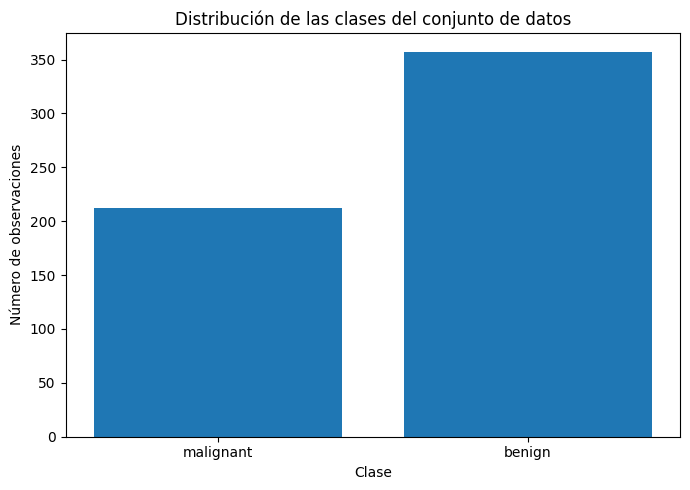

Observaciones de entrenamiento: 455
Observaciones de prueba: 114


In [2]:
# Gráfica de distribución
frecuencias = y.value_counts().sort_index()
nombres_clases = [datos.target_names[0], datos.target_names[1]]

plt.figure(figsize=(7, 5))
plt.bar(nombres_clases, frecuencias.values)
plt.title("Distribución de las clases del conjunto de datos")
plt.xlabel("Clase")
plt.ylabel("Número de observaciones")
plt.tight_layout()
plt.show()

# Partición 80/20 estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Observaciones de entrenamiento:", X_train.shape[0])
print("Observaciones de prueba:", X_test.shape[0])

# **SVM Lineal - Entrenamiento y Evaluación**

Accuracy: 0.9737
Precisión para maligno: 0.9535
Sensibilidad para maligno: 0.9762
F1-score para maligno: 0.9647


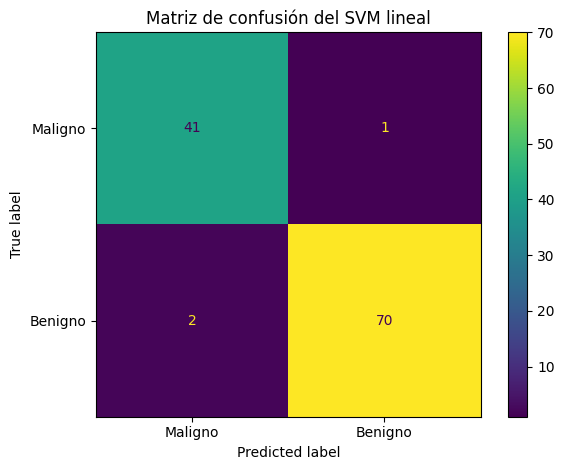

              precision    recall  f1-score   support

     Maligno       0.95      0.98      0.96        42
     Benigno       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [3]:
# Pipeline: Escalado estricto + SVM Lineal
modelo_lineal = Pipeline([
    ("escalado", StandardScaler()),
    ("clasificador", SVC(kernel="linear", C=1.0, probability=True, random_state=42))
])

modelo_lineal.fit(X_train, y_train)
pred_lineal = modelo_lineal.predict(X_test)

# Métricas (pos_label=0 porque 0 es maligno)
accuracy_lineal = accuracy_score(y_test, pred_lineal)
precision_lineal = precision_score(y_test, pred_lineal, pos_label=0, zero_division=0)
recall_lineal = recall_score(y_test, pred_lineal, pos_label=0, zero_division=0)
f1_lineal = f1_score(y_test, pred_lineal, pos_label=0, zero_division=0)

print(f"Accuracy: {accuracy_lineal:.4f}")
print(f"Precisión para maligno: {precision_lineal:.4f}")
print(f"Sensibilidad para maligno: {recall_lineal:.4f}")
print(f"F1-score para maligno: {f1_lineal:.4f}")

# Matriz de confusión
matriz = confusion_matrix(y_test, pred_lineal, labels=[0, 1])
visualizador = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=["Maligno", "Benigno"])
visualizador.plot()
plt.title("Matriz de confusión del SVM lineal")
plt.tight_layout()
plt.show()

# Reporte
print(classification_report(y_test, pred_lineal, labels=[0, 1], target_names=["Maligno", "Benigno"], zero_division=0))

# **SVM Kernel RBF y Comparativa**

In [4]:
# Pipeline: Escalado + SVM RBF
modelo_rbf = Pipeline([
    ("escalado", StandardScaler()),
    ("clasificador", SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=42))
])

modelo_rbf.fit(X_train, y_train)
pred_rbf = modelo_rbf.predict(X_test)

# Recopilar métricas en diccionarios para comparar
metricas_lineal = {
    "Modelo": "SVM lineal",
    "Accuracy": accuracy_lineal,
    "Precisión maligno": precision_lineal,
    "Sensibilidad maligno": recall_lineal,
    "F1 maligno": f1_lineal
}

metricas_rbf = {
    "Modelo": "SVM RBF",
    "Accuracy": accuracy_score(y_test, pred_rbf),
    "Precisión maligno": precision_score(y_test, pred_rbf, pos_label=0, zero_division=0),
    "Sensibilidad maligno": recall_score(y_test, pred_rbf, pos_label=0, zero_division=0),
    "F1 maligno": f1_score(y_test, pred_rbf, pos_label=0, zero_division=0)
}

tabla_comparacion = pd.DataFrame([metricas_lineal, metricas_rbf])
display(tabla_comparacion.round(4))

,Modelo,Accuracy,Precisión maligno,Sensibilidad maligno,F1 maligno
0,SVM lineal,0.9737,0.9535,0.9762,0.9647
1,SVM RBF,0.9825,0.9762,0.9762,0.9762


# **Curvas ROC-AUC**

ROC-AUC SVM lineal: 0.9964
ROC-AUC SVM RBF: 0.9950


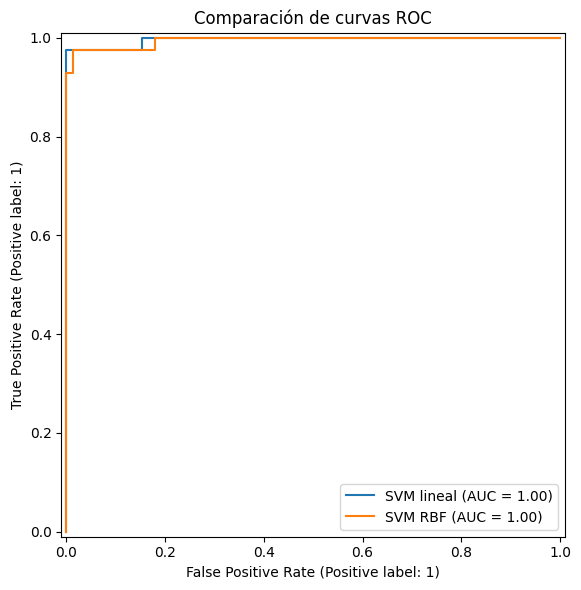

In [5]:
prob_lineal = modelo_lineal.predict_proba(X_test)
prob_rbf = modelo_rbf.predict_proba(X_test)

indice_maligno_lineal = list(modelo_lineal.named_steps["clasificador"].classes_).index(0)
indice_maligno_rbf = list(modelo_rbf.named_steps["clasificador"].classes_).index(0)

prob_maligno_lineal = prob_lineal[:, indice_maligno_lineal]
prob_maligno_rbf = prob_rbf[:, indice_maligno_rbf]

# Etiqueta binaria: 1 para maligno, 0 para benigno (solo para ROC)
y_test_maligno = (y_test == 0).astype(int)

auc_lineal = roc_auc_score(y_test_maligno, prob_maligno_lineal)
auc_rbf = roc_auc_score(y_test_maligno, prob_maligno_rbf)

print(f"ROC-AUC SVM lineal: {auc_lineal:.4f}")
print(f"ROC-AUC SVM RBF: {auc_rbf:.4f}")

fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(y_test_maligno, prob_maligno_lineal, name="SVM lineal", ax=ax)
RocCurveDisplay.from_predictions(y_test_maligno, prob_maligno_rbf, name="SVM RBF", ax=ax)
ax.set_title("Comparación de curvas ROC")
plt.tight_layout()
plt.show()

# **Reto - Optimización con GridSearchCV**

In [6]:
# Pipeline para la búsqueda (escalado dinámico en cada partición)
pipeline_reto = Pipeline([
    ("escalado", StandardScaler()),
    ("clasificador", SVC(kernel="rbf"))
])

parametros = {
    "clasificador__C": [0.1, 1, 10],
    "clasificador__gamma": ["scale", 0.01, 0.1]
}

validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Configurar búsqueda enfocada en maximizar el F1-score
busqueda = GridSearchCV(
    estimator=pipeline_reto,
    param_grid=parametros,
    scoring="f1",
    cv=validacion,
    refit=True,
    n_jobs=-1
)

# Entrenar transformando la clase objetivo a 1 = maligno para que el 'f1' funcione directo
busqueda.fit(X_train, (y_train == 0).astype(int))

print("Mejores hiperparámetros:", busqueda.best_params_)
print(f"Mejor F1 de validación cruzada: {busqueda.best_score_:.4f}")

mejor_modelo = busqueda.best_estimator_
pred_reto_binario = mejor_modelo.predict(X_test)

# Regresar a las etiquetas originales (0 = maligno, 1 = benigno)
pred_reto = np.where(pred_reto_binario == 1, 0, 1)

sensibilidad_reto = recall_score(y_test, pred_reto, pos_label=0, zero_division=0)
precision_reto = precision_score(y_test, pred_reto, pos_label=0, zero_division=0)
f1_reto = f1_score(y_test, pred_reto, pos_label=0, zero_division=0)
accuracy_reto = accuracy_score(y_test, pred_reto)

print(f"Accuracy final: {accuracy_reto:.4f}")
print(f"Precisión para maligno: {precision_reto:.4f}")
print(f"Sensibilidad para maligno: {sensibilidad_reto:.4f}")
print(f"F1-score para maligno: {f1_reto:.4f}")

Mejores hiperparámetros: {'clasificador__C': 10, 'clasificador__gamma': 0.01}
Mejor F1 de validación cruzada: 0.9668
Accuracy final: 0.9825
Precisión para maligno: 0.9762
Sensibilidad para maligno: 0.9762
F1-score para maligno: 0.9762
